<a href="https://colab.research.google.com/github/VY-MS123/NTUC_Capstone_MarketAnalysis/blob/main/Capstone_Market.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
# Replace with your actual URL (ensure it's a direct link to the CSV file)
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'

df = pd.read_csv(url)

# Display the first few rows
df.head()

,customer_id,first_name,last_name,gender,age,country,income
0,CS00001,Isadora,Porto,Female,19,Brazil,117196
1,CS00002,Hugo,Carreño,Male,33,Chile,49256
2,CS00003,René,Olivera,Male,65,Mexico,33434
3,CS00004,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,CS00005,Leonardo,Monteiro,Male,19,Brazil,32280


In [ ]:
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

df = pd.read_csv(url)

df.head()

,order_id,customer_id,product_name,description,price,discount,tax,order_date,quantity,shipping_cost,shipping_date
0,ODSHP00001,CS00001,Furniture,Transform your space with this stylish and fun...,645.52,0.37,0.02,26-05-2020,9,8.91,29-05-2020
1,ODSHP00002,CS00002,Dress,Look and feel your best with this elegant dress.,28.90,0.05,0.02,29-12-2022,9,13.95,29-12-2022
2,ODSHP00003,CS00003,Furniture,Transform your space with this stylish and fun...,3536.49,0.21,0.04,06-03-2021,3,36.42,06-03-2021
3,ODSHP00004,CS00004,Shoes,Step out in style with these fashionable shoes.,97.80,0.11,0.08,11-03-2020,7,9.35,13-03-2020
4,ODSHP00005,CS00005,Rugs,Add warmth and texture to your floors with the...,1785.38,0.13,0.00,12-03-2022,7,8.55,15-03-2022


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50000 non-null  object 
 1   customer_id    50000 non-null  object 
 2   product_name   50000 non-null  object 
 3   description    50000 non-null  object 
 4   price          50000 non-null  float64
 5   discount       50000 non-null  float64
 6   tax            50000 non-null  float64
 7   order_date     50000 non-null  object 
 8   quantity       50000 non-null  int64  
 9   shipping_cost  50000 non-null  float64
 10  shipping_date  50000 non-null  object 
dtypes: float64(4), int64(1), object(6)
memory usage: 4.2+ MB


In [ ]:
df.isnull().sum()


,0
order_id,0
customer_id,0
product_name,0
description,0
price,0
discount,0
tax,0
order_date,0
quantity,0
shipping_cost,0


In [ ]:
#change the Data type
columns_to_convert = ['order_id', 'customer_id', 'product_name']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['description']
df[columns_to_convert] = df[columns_to_convert].astype('string')

In [ ]:
columns_to_convert = ['order_date', 'shipping_date']
for col in columns_to_convert:
    df[col] = pd.to_datetime(df[col], format='%d-%m-%Y')

In [ ]:
#recheck data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       50000 non-null  string        
 1   customer_id    50000 non-null  string        
 2   product_name   50000 non-null  string        
 3   description    50000 non-null  string        
 4   price          50000 non-null  float64       
 5   discount       50000 non-null  float64       
 6   tax            50000 non-null  float64       
 7   order_date     50000 non-null  datetime64[ns]
 8   quantity       50000 non-null  int64         
 9   shipping_cost  50000 non-null  float64       
 10  shipping_date  50000 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(4), int64(1), string(4)
memory usage: 4.2 MB


In [ ]:
total_revenue = df["price"].sum()
total_orders = df["quantity"].sum()
avg_order_value = df["price"].mean()

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Units Sold: {total_orders:,}")
print(f"Average Sales Value per Item: ${avg_order_value:,.2f}")

Total Revenue: $63,796,343.63
Total Units Sold: 274,878
Average Sales Value per Item: $1,275.93


Objective 1
Regional Sales Performance & Grographic Market Analysis:
Evaluate Total Revenue transaction volume, and average order value across different geographic regions (Region) to identify high-performing markets and underperforming zones.

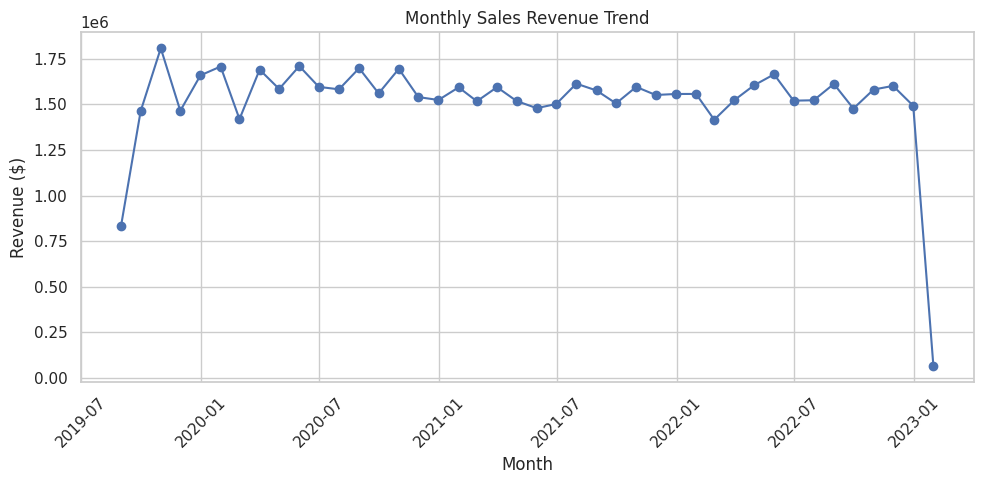

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the URL and parse order_date as datetime directly
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df = pd.read_csv(url, parse_dates=['order_date'], dayfirst=True)

# Calculate TotalSales as simply the sum of the price column per user context
df["TotalSales"] = df["price"]

# Group by month using TotalSales (which is equal to price)
monthly_sales = df.resample("ME", on="order_date")["TotalSales"].sum().reset_index()

# Plot Monthly Trend with correct Revenue definition
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales["order_date"],
    monthly_sales["TotalSales"],
    marker="o",
    color="b",
    linestyle="-",
)
plt.title("Monthly Sales Revenue Trend (Sum of Prices)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The highest sales result occurred in 2019, with approximately 1.75 million.

The sales drop significantly in year 2023 should not be interpreted as genuine seasonal declines because those are incomplete months as sales up to 16 Jan 2023 being taken up for this analysis.

Finding: Monthly revenue is otherwise relatively stable, generally falling between approximately 1.6 million and 1.5 million. Seasonal conclusions should be calculated using complete months only.

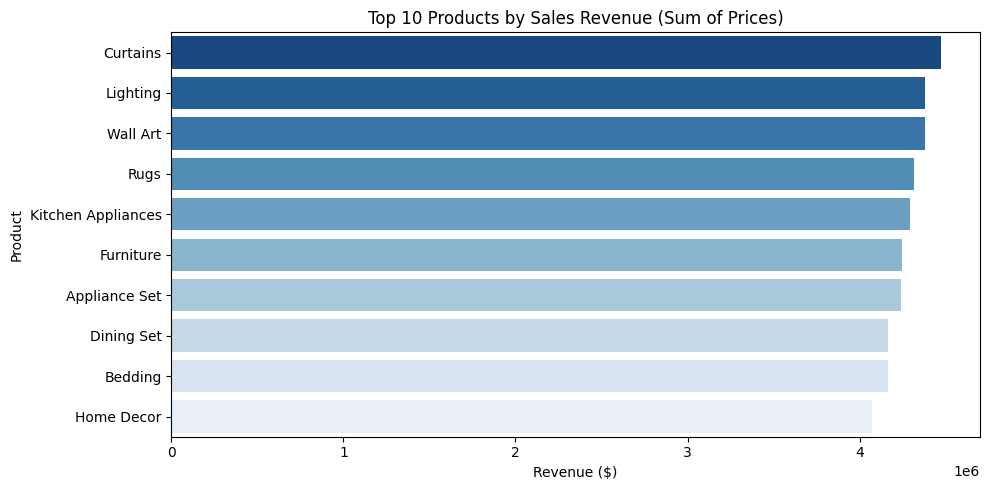

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate TotalSales as simply the sum of prices
df["TotalSales"] = df['price']

# Top 10 products by revenue (sum of prices)
top_products = (
    df.groupby("product_name")["TotalSales"].sum().nlargest(10).reset_index()
)

# Plot Top Products
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_products,
    x="TotalSales",
    y="product_name",
    hue="product_name",
    palette="Blues_r",
    legend=False
)
plt.title("Top 10 Products by Sales Revenue (Sum of Prices)")
plt.xlabel("Revenue ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Based on the graph above, Curtains ($4.48M), Lighting ($4.38M), Wall Art ($4.38M), Rugs ($4.31M) and Kitchen Appliances ($4.29M) are the major contributors for total revenue, which representing 34.23% of total revenue.

In [14]:
import pandas as pd

# 1. Load the customer and purchase datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# 2. Calculate spending for each purchase record (sales = price)
purch_df['TotalSpending'] = purch_df['price']

# 3. Aggregate spending by customer_id
customer_spending = purch_df.groupby('customer_id')['TotalSpending'].sum().reset_index()

# 4. Merge with customer details to get name and demographic information
top_spenders = pd.merge(customer_spending, cust_df, on='customer_id')

# 5. Sort by TotalSpending in descending order and select the top 10
top_10_spenders = top_spenders.sort_values(by='TotalSpending', ascending=False).head(10)

# Display results
display(top_10_spenders[['customer_id', 'first_name', 'last_name', 'country', 'TotalSpending']])

,customer_id,first_name,last_name,country,TotalSpending
608,CS00609,Martín,de la Torre,Mexico,90616.95
170,CS00171,André,da Cruz,Brazil,89808.94
833,CS00834,Edith,Ortega,Colombia,89101.10
383,CS00384,Ariel,Contreras,Chile,88677.07
321,CS00322,Pedro,Silva,Brazil,87651.70
335,CS00336,Alberto,Alfonso,Colombia,87482.50
444,CS00445,Julio César,Nieves,Mexico,85754.16
350,CS00351,Omar,Quintero,Colombia,85351.37
941,CS00942,Leidy,Guerrero,Colombia,84804.35
87,CS00088,Bárbara,Rodríguez,Chile,84476.94


The table represents the Top 10 customers ranked by Total Spending, indicating the most valuable customers based on cumulative purchase value.

Based on the analysis, there is no significant customer concentration risk, as spending levels among the top customers are relatively similar and no single customer contributes a disproportionately large share of total revenue.

Top 5 Countries by Total Revenue (Sum of Prices):


,country,TotalRevenue
2,Colombia,"$18,005,623.56"
1,Chile,"$16,166,076.12"
3,Mexico,"$14,898,656.78"
0,Brazil,"$14,725,987.17"


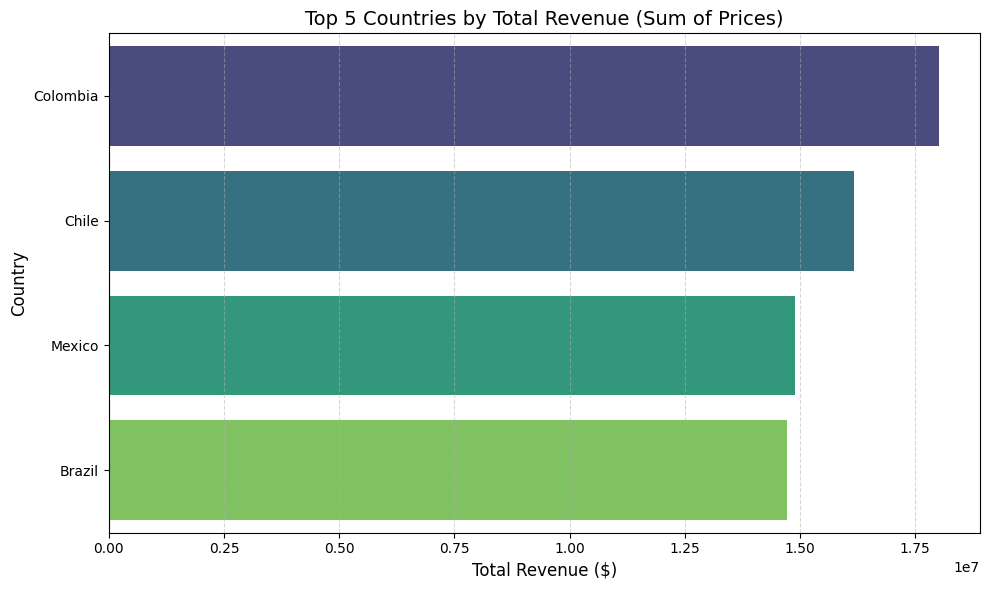

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we use purchase and customer datasets
cust_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/customer.csv'
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'

cust_df = pd.read_csv(cust_url)
purch_df = pd.read_csv(purch_url)

# Calculate revenue based on price alone (sales = price)
purch_df['TotalRevenue'] = purch_df['price']

# Merge datasets on customer_id to get customer geographic info
merged_df = pd.merge(purch_df, cust_df, on='customer_id')

# Aggregate total revenue by country
country_revenue = merged_df.groupby('country')['TotalRevenue'].sum().reset_index()

# Select the top 5 countries by revenue
top_5_countries = country_revenue.sort_values(by='TotalRevenue', ascending=False).head(5)

# Display the tabular summary
print("Top 5 Countries by Total Revenue (Sum of Prices):")
display(top_5_countries.style.format({'TotalRevenue': '${:,.2f}'}))

# Visualize the results
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_5_countries,
    x='TotalRevenue',
    y='country',
    hue='country',
    palette='viridis',
    legend=False
)
plt.title('Top 5 Countries by Total Revenue (Sum of Prices)', fontsize=14)
plt.xlabel('Total Revenue ($)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Revenue Analysis by Country

The chart presents the total revenue generated by customers from each country, providing insights into the company's strongest and weakest markets.

The analysis shows that Colombia is the leading revenue-generating market, followed by Chile, Mexico, and Brazil. While Colombia demonstrates the strongest overall performance, all four countries contribute significantly to total sales revenue. The relatively balanced distribution of revenue across countries indicates a diversified customer portfolio and reduces geographic concentration risk. To maximise future growth, the company should continue strengthening its position in Colombia while exploring strategies to improve customer spending and market penetration in Brazil.

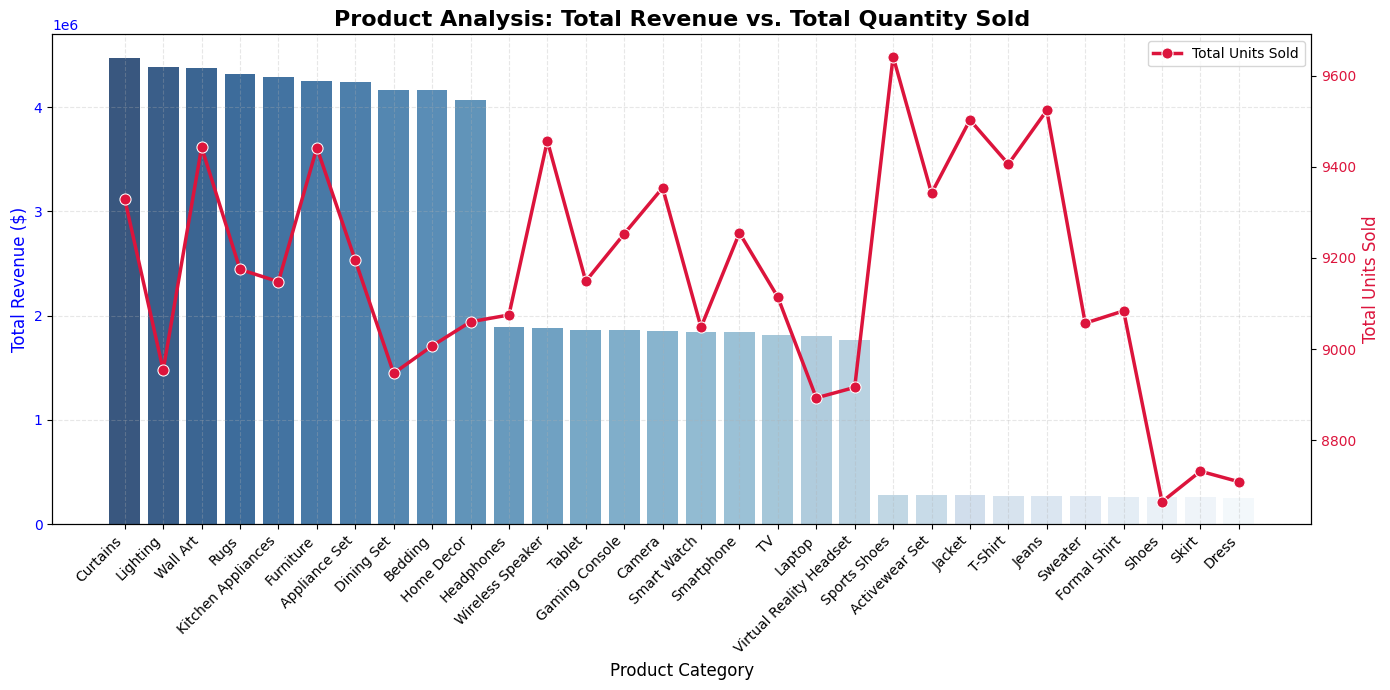

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
purch_url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df_purch = pd.read_csv(purch_url)

# 2. Aggregate both revenue (price) and quantity (units sold) by product
product_stats = df_purch.groupby('product_name').agg(
    TotalRevenue=('price', 'sum'),
    TotalQuantity=('quantity', 'sum')
).reset_index()

# Sort by Revenue for clean visualization flow
product_stats = product_stats.sort_values(by='TotalRevenue', ascending=False)

# 3. Create a dual-axis plot
fig, ax1 = plt.subplots(figsize=(14, 7))

# Primary axis: Bar chart for Total Revenue
sns.barplot(
    data=product_stats,
    x='product_name',
    y='TotalRevenue',
    ax=ax1,
    palette='Blues_r',
    hue='product_name',
    legend=False,
    alpha=0.85
)
ax1.set_title('Product Analysis: Total Revenue vs. Total Quantity Sold', fontsize=16, fontweight='bold')
ax1.set_xlabel('Product Category', fontsize=12)
ax1.set_ylabel('Total Revenue ($)', color='b', fontsize=12)
ax1.tick_params(axis='y', labelcolor='b')

# Set correct tick locations first to prevent warnings
ax1.set_xticks(range(len(product_stats)))
ax1.set_xticklabels(product_stats['product_name'], rotation=45, ha='right')

# Secondary axis: Line chart with markers for Quantity Sold
ax2 = ax1.twinx()
sns.lineplot(
    data=product_stats,
    x='product_name',
    y='TotalQuantity',
    ax=ax2,
    color='crimson',
    marker='o',
    linewidth=2.5,
    markersize=8,
    sort=False,
    label='Total Units Sold'
)
ax2.set_ylabel('Total Units Sold', color='crimson', fontsize=12)
ax2.tick_params(axis='y', labelcolor='crimson')
ax2.legend(loc='upper right')

ax1.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Product Analysis: Total Revenue vs. Total Quantity Sold

This chart compares total revenue (blue bars) and total units sold (red line) across different product categories. The analysis helps identify whether revenue is driven by high sales volume, high product value, or a combination of both.

The analysis reveals that home furnishing and décor products are the company's primary revenue drivers, with Curtains, Lighting, and Wall Art generating the highest sales revenue. In contrast, fashion products such as Sports Shoes, Jeans, and Jackets achieve the highest sales volumes but contribute significantly less revenue per unit sold. This indicates two distinct business strategies within the product portfolio: premium products drive revenue, while fashion products drive demand and customer traffic. To maximise profitability, management should focus on expanding high-revenue home-related products while leveraging high-volume fashion categories for cross-selling and customer engagement opportunities.

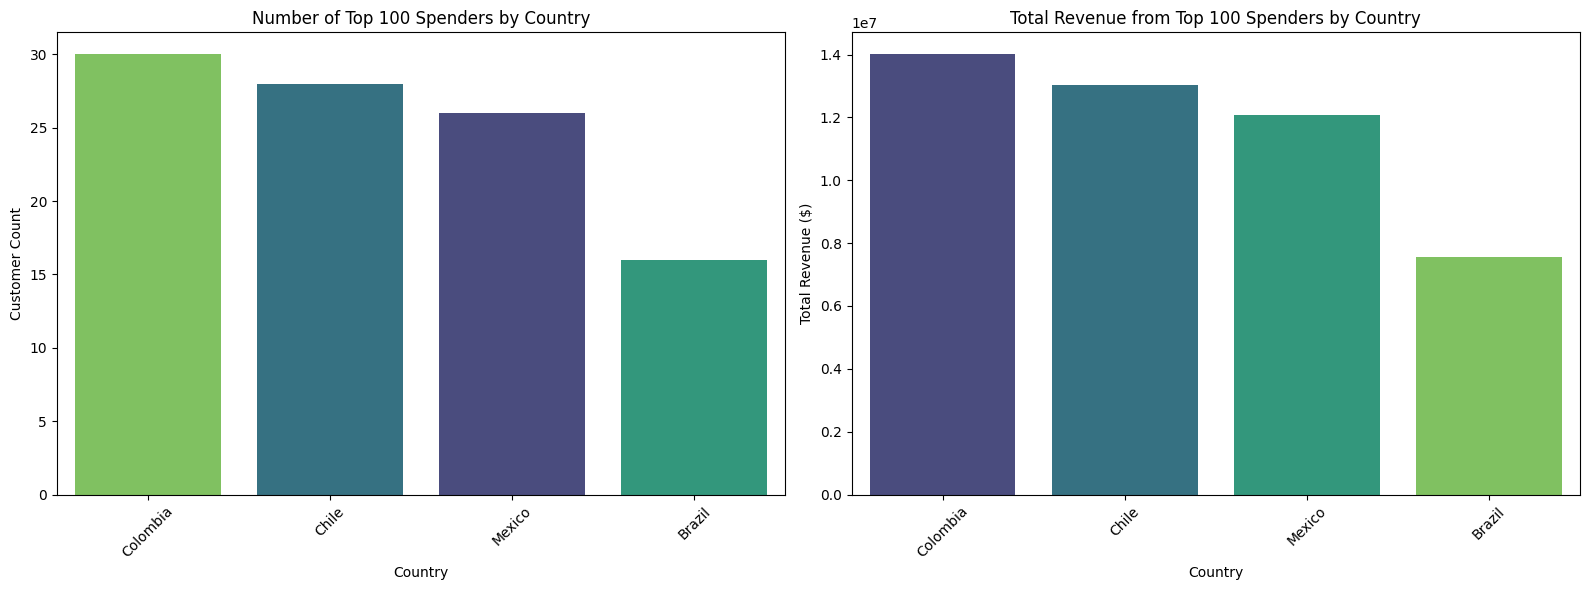

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Let's define the top spenders (e.g., top 100 highest-spending customers)
top_100_spenders = top_spenders.sort_values(by='TotalSpending', ascending=False).head(100)

# Set up the plotting grid (1 row, 2 columns for count and total value)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Count of Top 100 Spenders by Country
sns.countplot(
    data=top_100_spenders,
    x='country',
    ax=axes[0],
    hue='country',
    palette='viridis',
    legend=False,
    order=top_100_spenders['country'].value_counts().index
)
axes[0].set_title('Number of Top 100 Spenders by Country')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Customer Count')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Total Revenue Contributed by Top 100 Spenders by Country
country_spending = top_100_spenders.groupby('country')['TotalSpending'].sum().reset_index().sort_values(by='TotalSpending', ascending=False)
sns.barplot(
    data=country_spending,
    x='country',
    y='TotalSpending',
    ax=axes[1],
    hue='country',
    palette='viridis',
    legend=False
)
axes[1].set_title('Total Revenue from Top 100 Spenders by Country')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Total Revenue ($)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Pearson correlation coefficient (Shipping Cost vs. Total Sales): 0.0067


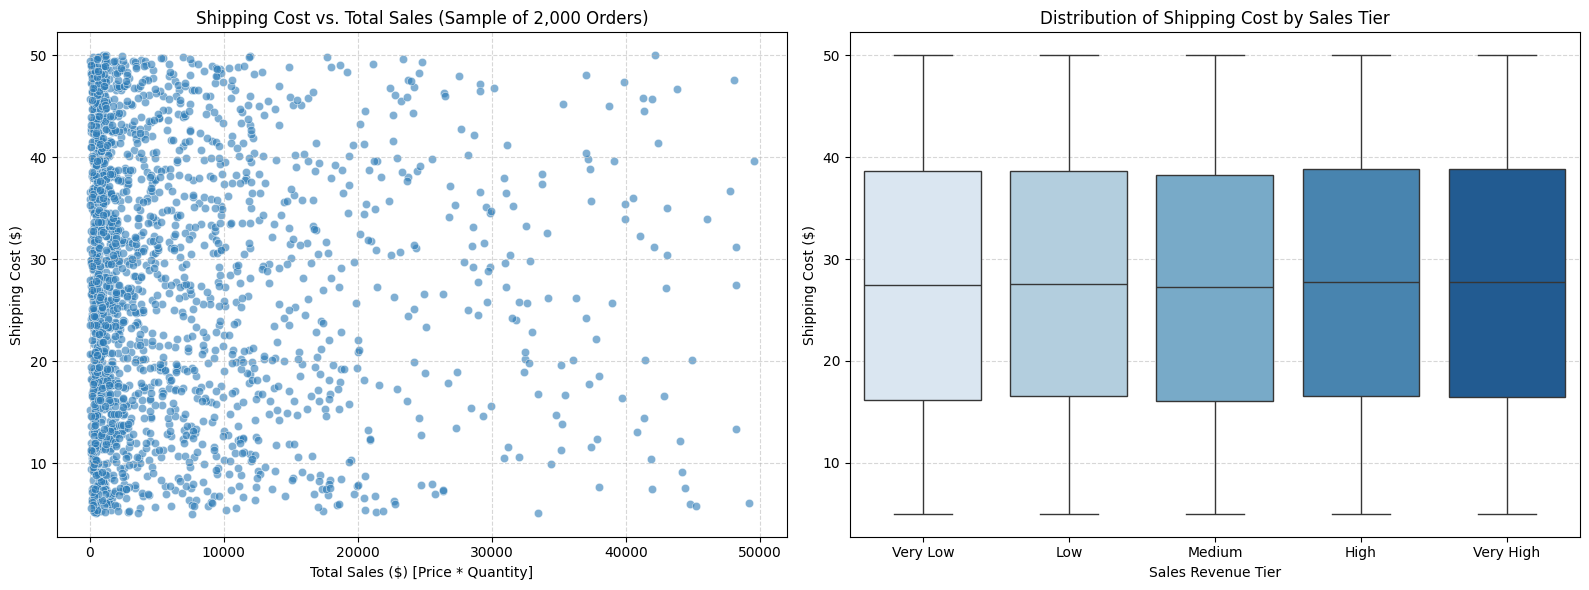

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Explicitly load the purchase dataset
url = 'https://raw.githubusercontent.com/VY-MS123/NTUC_Capstone_MarketAnalysis/refs/heads/main/purchase.csv'
df = pd.read_csv(url)

# Calculate TotalSales using price * quantity
df['TotalSales'] = df['price'] * df['quantity']

# Calculate correlation between shipping cost and corrected Total Sales
shipping_sales_corr = df['shipping_cost'].corr(df['TotalSales'])
print(f"Pearson correlation coefficient (Shipping Cost vs. Total Sales): {shipping_sales_corr:.4f}")

# Create a visualization of the relationship
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter plot of Shipping Cost vs. Total Sales (using a sample of 2,000 to avoid overplotting)
sns.scatterplot(
    data=df.sample(2000, random_state=42),
    x='TotalSales',
    y='shipping_cost',
    alpha=0.6,
    color='#2c7bb6',
    ax=axes[0]
)
axes[0].set_title('Shipping Cost vs. Total Sales (Sample of 2,000 Orders)')
axes[0].set_xlabel('Total Sales ($) [Price * Quantity]')
axes[0].set_ylabel('Shipping Cost ($)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Boxplot of shipping costs across different sales tiers
# Creating 5 quantiles (bins) for Total Sales to see how shipping costs behave in different sales tiers
df['Sales_Tier'] = pd.qcut(df['TotalSales'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])
sns.boxplot(
    data=df,
    x='Sales_Tier',
    y='shipping_cost',
    palette='Blues',
    hue='Sales_Tier',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Distribution of Shipping Cost by Sales Tier')
axes[1].set_xlabel('Sales Revenue Tier')
axes[1].set_ylabel('Shipping Cost ($)')
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The relationship between Shipping Cost and Total Sales appears to be weak or negligible based on both the scatter plot and box plot.

The visualisations indicate a weak relationship between shipping cost and total sales. Shipping costs remain relatively consistent regardless of whether an order generates low or high revenue. This suggests that shipping cost is not a major driver of customer spending behaviour and is likely influenced by operational or logistical factors rather than order value alone.

Pearson correlation coefficient between Age and Total Spending: 0.0564


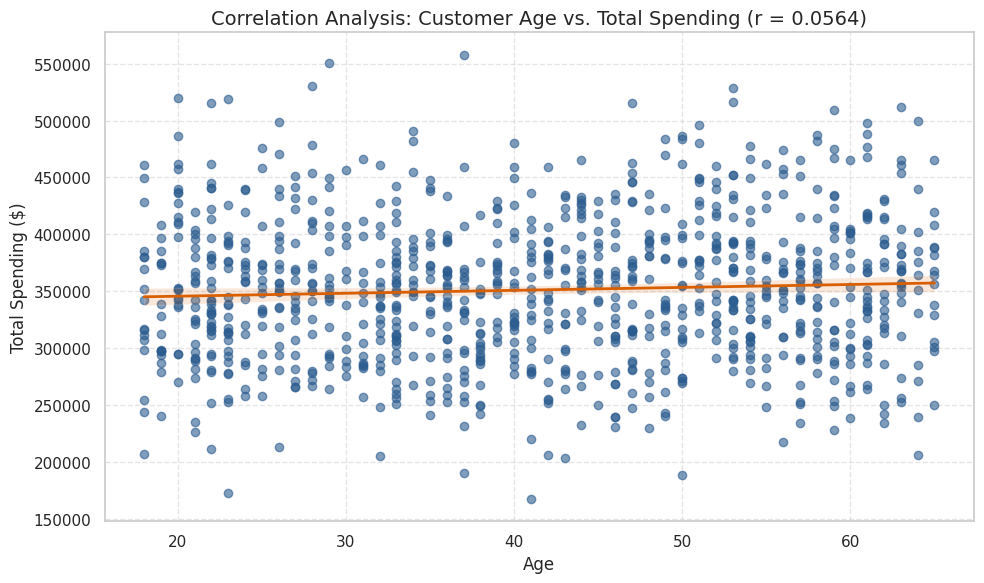

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Pearson correlation coefficient
correlation = top_spenders['age'].corr(top_spenders['TotalSpending'])
print(f"Pearson correlation coefficient between Age and Total Spending: {correlation:.4f}")

# 2. Plot Scatter Plot with a Regression Line
plt.figure(figsize=(10, 6))
sns.regplot(
    data=top_spenders,
    x='age',
    y='TotalSpending',
    scatter_kws={'alpha': 0.6, 'color': '#2b5c8f'},
    line_kws={'color': '#d95f02', 'linewidth': 2}
)

plt.title(f'Correlation Analysis: Customer Age vs. Total Spending (r = {correlation:.4f})', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Total Spending ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Pearson correlation coefficient between Income and Total Spending: 0.0223


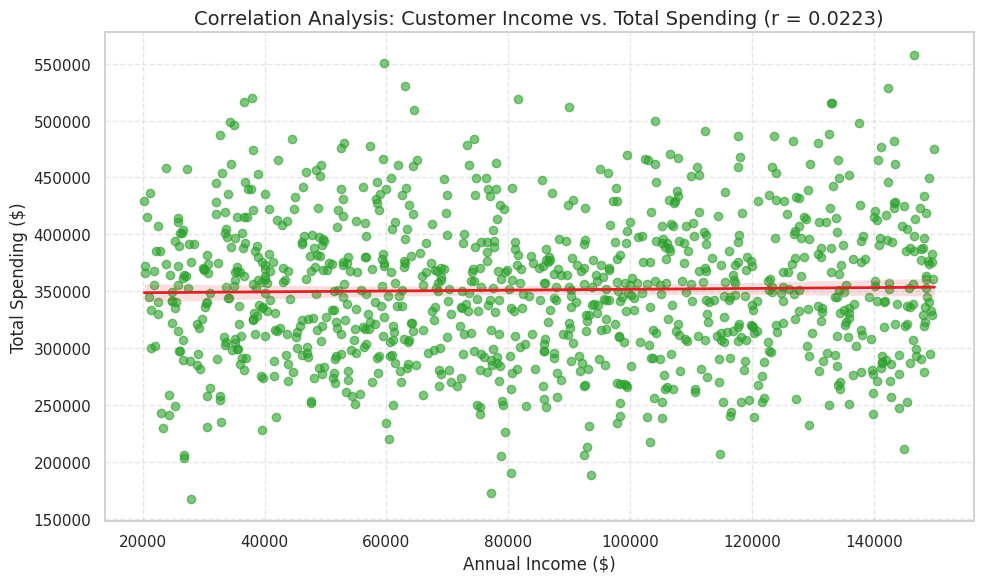

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Pearson correlation coefficient between income and total spending
income_correlation = top_spenders['income'].corr(top_spenders['TotalSpending'])
print(f"Pearson correlation coefficient between Income and Total Spending: {income_correlation:.4f}")

# 2. Plot Scatter Plot with a Regression Line
plt.figure(figsize=(10, 6))
sns.regplot(
    data=top_spenders,
    x='income',
    y='TotalSpending',
    scatter_kws={'alpha': 0.6, 'color': '#2ca02c'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)

plt.title(f'Correlation Analysis: Customer Income vs. Total Spending (r = {income_correlation:.4f})', fontsize=14)
plt.xlabel('Annual Income ($)', fontsize=12)
plt.ylabel('Total Spending ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Correlation between Discount and Quantity Purchased: -0.0010
Correlation between Discount and Total Sales Revenue: -0.0003

Summary Statistics by Discount Tier:


,Average_Quantity,Average_Sales,Order_Count
Discount_Tier,,,
0% (No Discount),5.721174,7777.733208,477
1% - 15% (Low),5.496724,7065.278027,15111
16% - 30% (Medium),5.499165,6955.397794,14979
31%+ (High),5.491484,7023.543644,19433


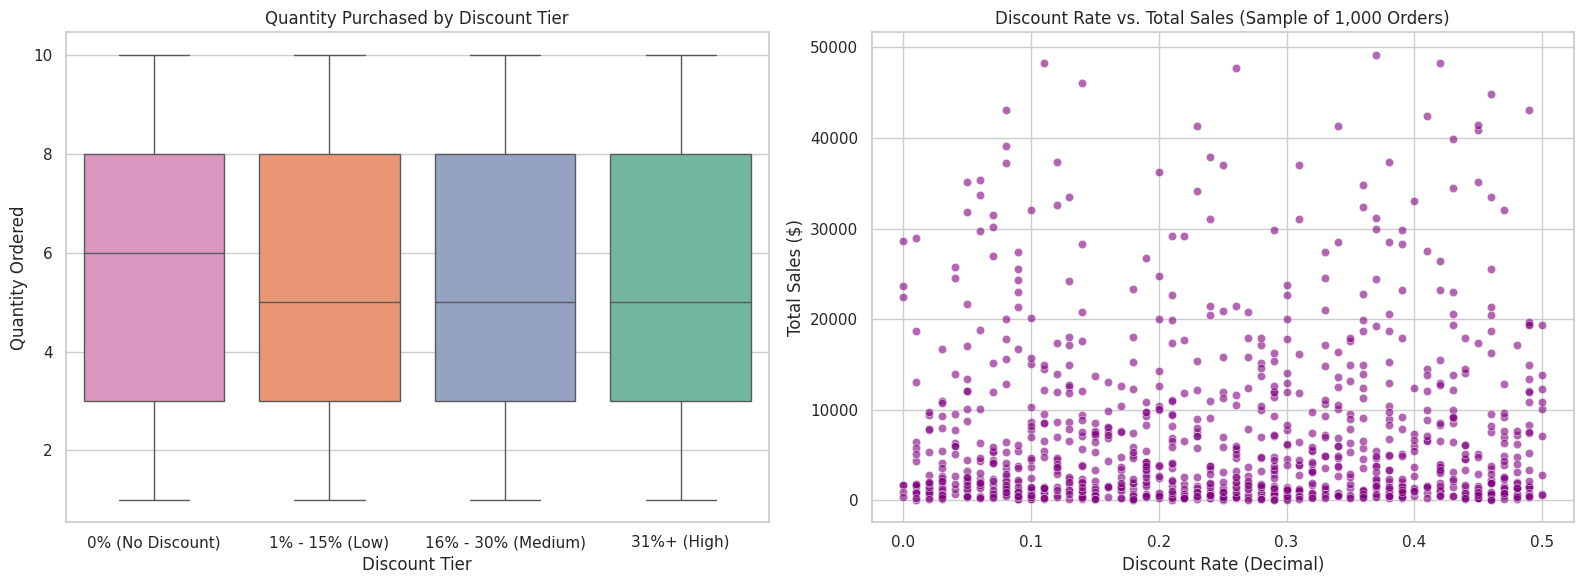

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we are using the primary purchase dataframe
df['TotalSales'] = df['quantity'] * df['price']

# 1. Calculate Correlation
corr_qty = df['discount'].corr(df['quantity'])
corr_sales = df['discount'].corr(df['TotalSales'])
print(f"Correlation between Discount and Quantity Purchased: {corr_qty:.4f}")
print(f"Correlation between Discount and Total Sales Revenue: {corr_sales:.4f}")

# 2. Bin discounts to see categorical impact
def bin_discount(discount):
    if discount == 0:
        return '0% (No Discount)'
    elif discount <= 0.15:
        return '1% - 15% (Low)'
    elif discount <= 0.30:
        return '16% - 30% (Medium)'
    else:
        return '31%+ (High)'

df['Discount_Tier'] = df['discount'].apply(bin_discount)
discount_grouped = df.groupby('Discount_Tier').agg(
    Average_Quantity=('quantity', 'mean'),
    Average_Sales=('TotalSales', 'mean'),
    Order_Count=('order_id', 'count')
).reindex(['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'])

print("\nSummary Statistics by Discount Tier:")
display(discount_grouped)

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Discount vs Quantity (Boxplot over Tiers)
sns.boxplot(
    data=df,
    x='Discount_Tier',
    y='quantity',
    ax=axes[0],
    order=['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'],
    palette='Set2',
    hue='Discount_Tier',
    legend=False
)
axes[0].set_title('Quantity Purchased by Discount Tier')
axes[0].set_xlabel('Discount Tier')
axes[0].set_ylabel('Quantity Ordered')

# Plot 2: Scatter plot of Discount vs Total Sales to check overall distribution
sns.scatterplot(
    data=df.sample(1000, random_state=42),  # sample to avoid overplotting
    x='discount',
    y='TotalSales',
    ax=axes[1],
    alpha=0.6,
    color='purple'
)
axes[1].set_title('Discount Rate vs. Total Sales (Sample of 1,000 Orders)')
axes[1].set_xlabel('Discount Rate (Decimal)')
axes[1].set_ylabel('Total Sales ($)')

plt.tight_layout()
plt.show()

Correlation between Discount and Profit Margin %: -0.8592

Profit Metrics by Discount Tier:


,Average_Profit_Margin,Average_Estimated_Profit,Average_Discount,Order_Count
Discount_Tier,,,,
0% (No Discount),97.218046,7751.300734,0.000000,477
1% - 15% (Low),88.946151,6474.493417,0.079531,15111
16% - 30% (Medium),73.823906,5327.825372,0.229788,14979
31%+ (High),56.697910,4166.955288,0.401998,19433


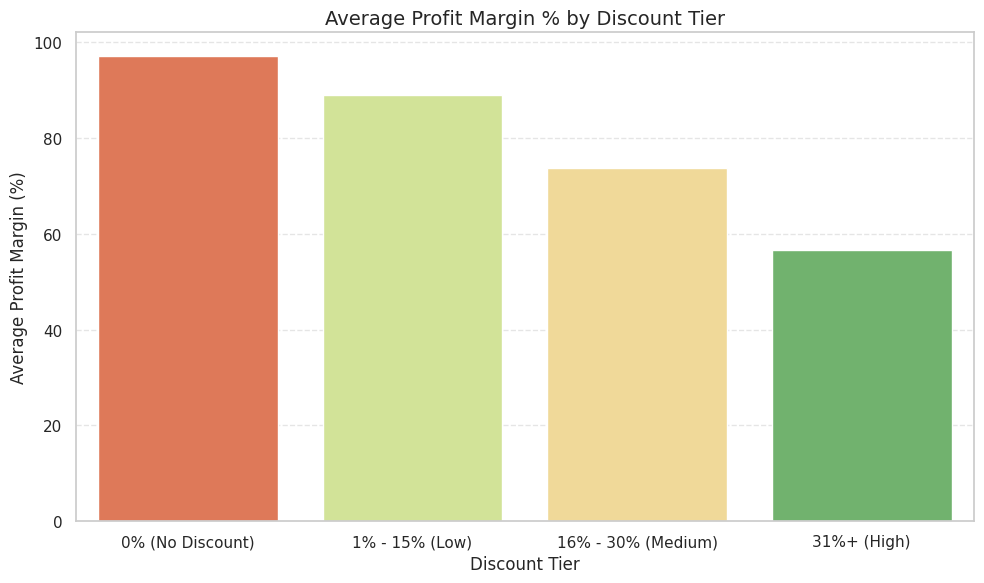

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Net Revenue and Estimated Profit Margin
# Let's assume Profit = Net Revenue (after discount) - shipping_cost + tax
df['TotalSales'] = df['quantity'] * df['price']
df['Net_Revenue'] = df['TotalSales'] * (1 - df['discount'])
df['Estimated_Profit'] = df['Net_Revenue'] - df['shipping_cost'] + df['tax']

# Profit Margin %
df['Profit_Margin_Percent'] = (df['Estimated_Profit'] / df['TotalSales']) * 100

# 2. Analyze correlation
margin_corr = df['discount'].corr(df['Profit_Margin_Percent'])
print(f"Correlation between Discount and Profit Margin %: {margin_corr:.4f}")

# 3. Group by discount tiers
profit_grouped = df.groupby('Discount_Tier').agg(
    Average_Profit_Margin=('Profit_Margin_Percent', 'mean'),
    Average_Estimated_Profit=('Estimated_Profit', 'mean'),
    Average_Discount=('discount', 'mean'),
    Order_Count=('order_id', 'count')
).reindex(['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'])

print("\nProfit Metrics by Discount Tier:")
display(profit_grouped)

# 4. Visualization
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x='Discount_Tier',
    y='Profit_Margin_Percent',
    order=['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'],
    palette='RdYlGn_r',
    hue='Discount_Tier',
    legend=False,
    errorbar=None
)
plt.title('Average Profit Margin % by Discount Tier', fontsize=14)
plt.xlabel('Discount Tier', fontsize=12)
plt.ylabel('Average Profit Margin (%)', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Format and display the summary table
summary_table = profit_grouped.copy()
summary_table['Average_Profit_Margin'] = summary_table['Average_Profit_Margin'].map('{:.2f}%'.format)
summary_table['Average_Estimated_Profit'] = summary_table['Average_Estimated_Profit'].map('${:,.2f}'.format)
summary_table['Average_Discount'] = (summary_table['Average_Discount'] * 100).map('{:.2f}%'.format)
summary_table['Order_Count'] = summary_table['Order_Count'].map('{:,}'.format)

summary_table.columns = ['Avg Profit Margin (%)', 'Avg Net Profit ($)', 'Avg Discount (%)', 'Total Orders']
display(summary_table)

,Avg Profit Margin (%),Avg Net Profit ($),Avg Discount (%),Total Orders
Discount_Tier,,,,
0% (No Discount),97.22%,"$7,751.30",0.00%,477
1% - 15% (Low),88.95%,"$6,474.49",7.95%,"15,111"
16% - 30% (Medium),73.82%,"$5,327.83",22.98%,"14,979"
31%+ (High),56.70%,"$4,166.96",40.20%,"19,433"


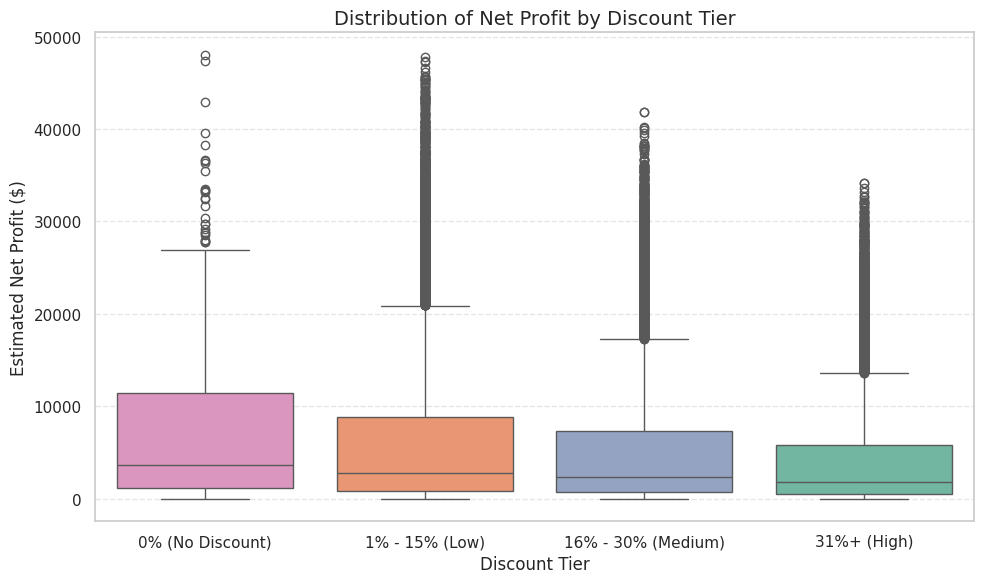

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='Discount_Tier',
    y='Estimated_Profit',
    order=['0% (No Discount)', '1% - 15% (Low)', '16% - 30% (Medium)', '31%+ (High)'],
    palette='Set2',
    hue='Discount_Tier',
    legend=False
)

plt.title('Distribution of Net Profit by Discount Tier', fontsize=14)
plt.xlabel('Discount Tier', fontsize=12)
plt.ylabel('Estimated Net Profit ($)', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Product Performance Insights (Sorted by Total Revenue):


,Total_Revenue,Units_Sold,Average_Price,Average_Discount,Transaction_Count
product_name,,,,,
Curtains,"$24,685,964.16","9,329","$2,640.30",24.30%,"1,695"
Wall Art,"$24,406,094.28","9,443","$2,565.35",25.65%,"1,707"
Lighting,"$23,896,803.81","8,954","$2,652.77",25.12%,"1,652"
Furniture,"$23,697,854.47","9,442","$2,505.65",24.99%,"1,695"
Kitchen Appliances,"$23,638,293.50","9,148","$2,575.45",24.93%,"1,666"
Rugs,"$23,537,622.04","9,175","$2,581.99",24.97%,"1,671"
Appliance Set,"$23,442,196.54","9,195","$2,549.73",25.13%,"1,663"
Dining Set,"$23,407,025.82","8,947","$2,613.15",24.82%,"1,594"
Home Decor,"$22,764,269.34","9,060","$2,496.92",24.71%,"1,631"


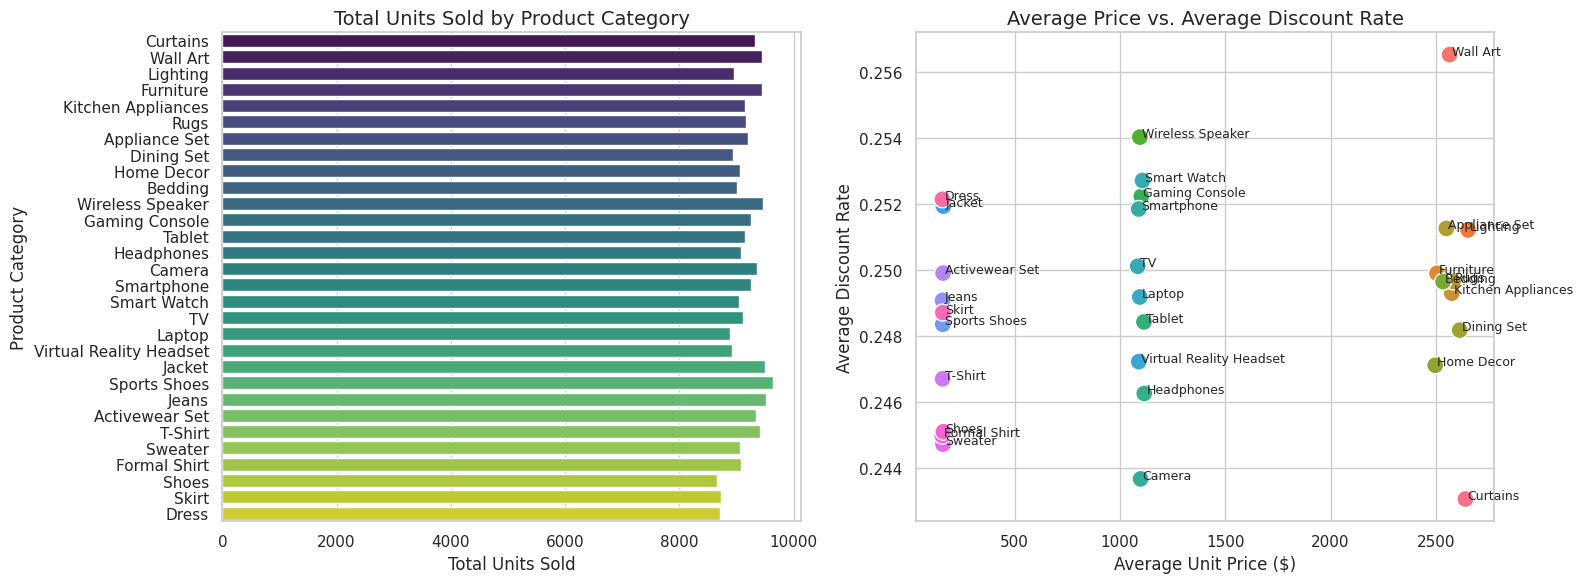

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate metrics by product
product_insights = df.groupby('product_name').agg(
    Total_Revenue=('TotalSales', 'sum'),
    Units_Sold=('quantity', 'sum'),
    Average_Price=('price', 'mean'),
    Average_Discount=('discount', 'mean'),
    Transaction_Count=('order_id', 'count')
).sort_values(by='Total_Revenue', ascending=False)

print("Product Performance Insights (Sorted by Total Revenue):")
display(product_insights.style.format({
    'Total_Revenue': '${:,.2f}',
    'Units_Sold': '{:,}',
    'Average_Price': '${:,.2f}',
    'Average_Discount': '{:.2%}',
    'Transaction_Count': '{:,}'
}))

# 2. Visualize Product Sales Mix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Left: Total Units Sold by Product
sns.barplot(
    data=product_insights.reset_index(),
    x='Units_Sold',
    y='product_name',
    ax=axes[0],
    palette='viridis',
    hue='product_name',
    legend=False
)
axes[0].set_title('Total Units Sold by Product Category', fontsize=14)
axes[0].set_xlabel('Total Units Sold')
axes[0].set_ylabel('Product Category')

# Plot Right: Average Discount Rate vs Average Price by Product Category
sns.scatterplot(
    data=product_insights.reset_index(),
    x='Average_Price',
    y='Average_Discount',
    hue='product_name',
    s=150,
    ax=axes[1]
)
for i, row in product_insights.reset_index().iterrows():
    axes[1].text(row['Average_Price'] + 10, row['Average_Discount'], row['product_name'], fontsize=9)

axes[1].set_title('Average Price vs. Average Discount Rate', fontsize=14)
axes[1].set_xlabel('Average Unit Price ($)')
axes[1].set_ylabel('Average Discount Rate')
axes[1].legend().remove()

plt.tight_layout()
plt.show()